# Why Seaborn?

- provides a layer of abstraction hence simpler to use
- better aesthetics
- more graphs included

# Seaborn Roadmap

Types of Functions

- Figure Level
- Axis Level

# Main Classification

- Relational Plot
- Distribution Plot
- Categorical Plot
- Regression Plot
- Matrix Plot
- Multiplots

https://seaborn.pydata.org/api.html

# 1. Relational Plot
- to see the statistical relation between 2 or more variables.
- Bivariate Analysis

Plots under this section
- scatterplot
- lineplot

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [3]:
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='total_bill', ylabel='tip'>

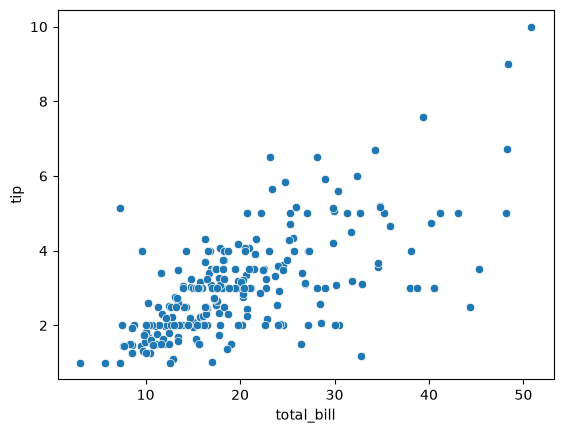

In [ ]:
# scatter plot -> axes level
sns.scatterplot(data=tips, x='total_bill',y='tip')

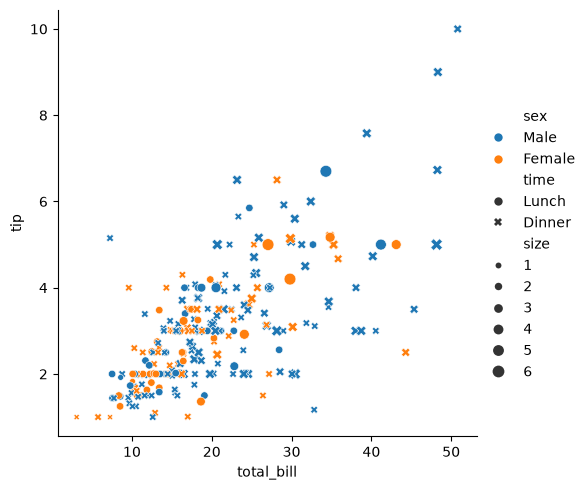

In [11]:
# scatter using relplot -> size and hue -> figure level
sns.relplot(data=tips,x='total_bill',y='tip',kind='scatter',hue='sex',style='time',size='size')

In [ ]:
# style semantics

In [15]:
gap = px.data.gapminder()
gap

temp_df = gap[gap['country'] == 'India']
temp_df

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
696,India,Asia,1952,37.373,372000000,546.565749,IND,356
697,India,Asia,1957,40.249,409000000,590.061996,IND,356
698,India,Asia,1962,43.605,454000000,658.347151,IND,356
699,India,Asia,1967,47.193,506000000,700.770611,IND,356
700,India,Asia,1972,50.651,567000000,724.032527,IND,356
701,India,Asia,1977,54.208,634000000,813.337323,IND,356
702,India,Asia,1982,56.596,708000000,855.723538,IND,356
703,India,Asia,1987,58.553,788000000,976.512676,IND,356
704,India,Asia,1992,60.223,872000000,1164.406809,IND,356
705,India,Asia,1997,61.765,959000000,1458.817442,IND,356


<Axes: xlabel='year', ylabel='lifeExp'>

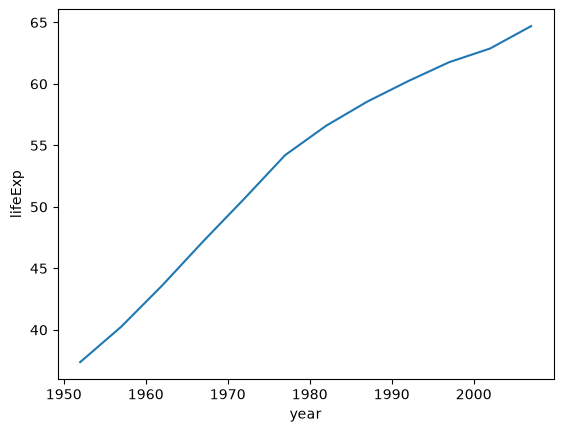

In [16]:
# line plot
sns.lineplot(temp_df,x='year',y='lifeExp')

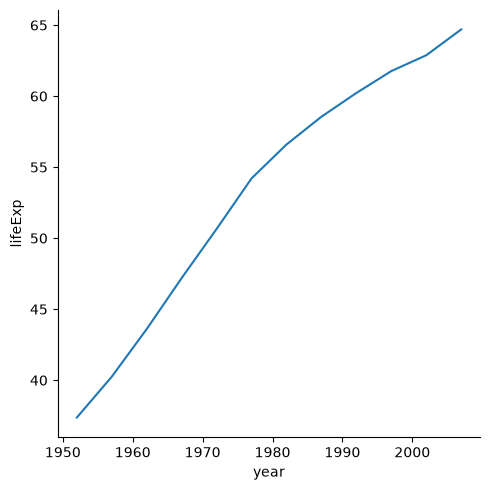

In [17]:
# using relpplot

sns.relplot(data=temp_df,x='year',y='lifeExp',kind='line')

In [24]:
temp_df = gap[gap['country'].isin(['India','Brazil','Germany'])]

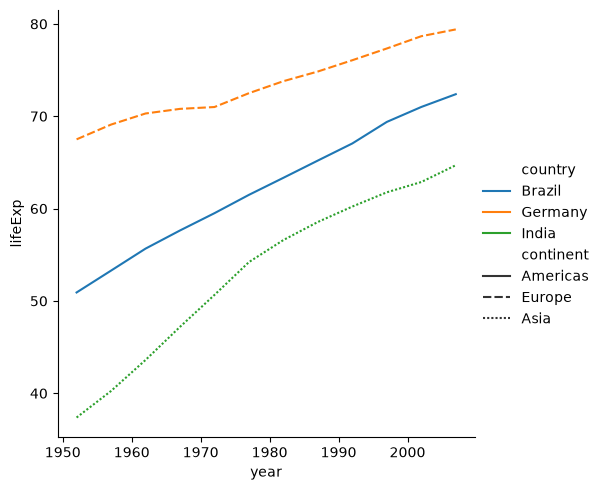

In [26]:
# hue -> style
sns.relplot(data=temp_df,x='year',y='lifeExp',hue='country',kind='line',style='continent')

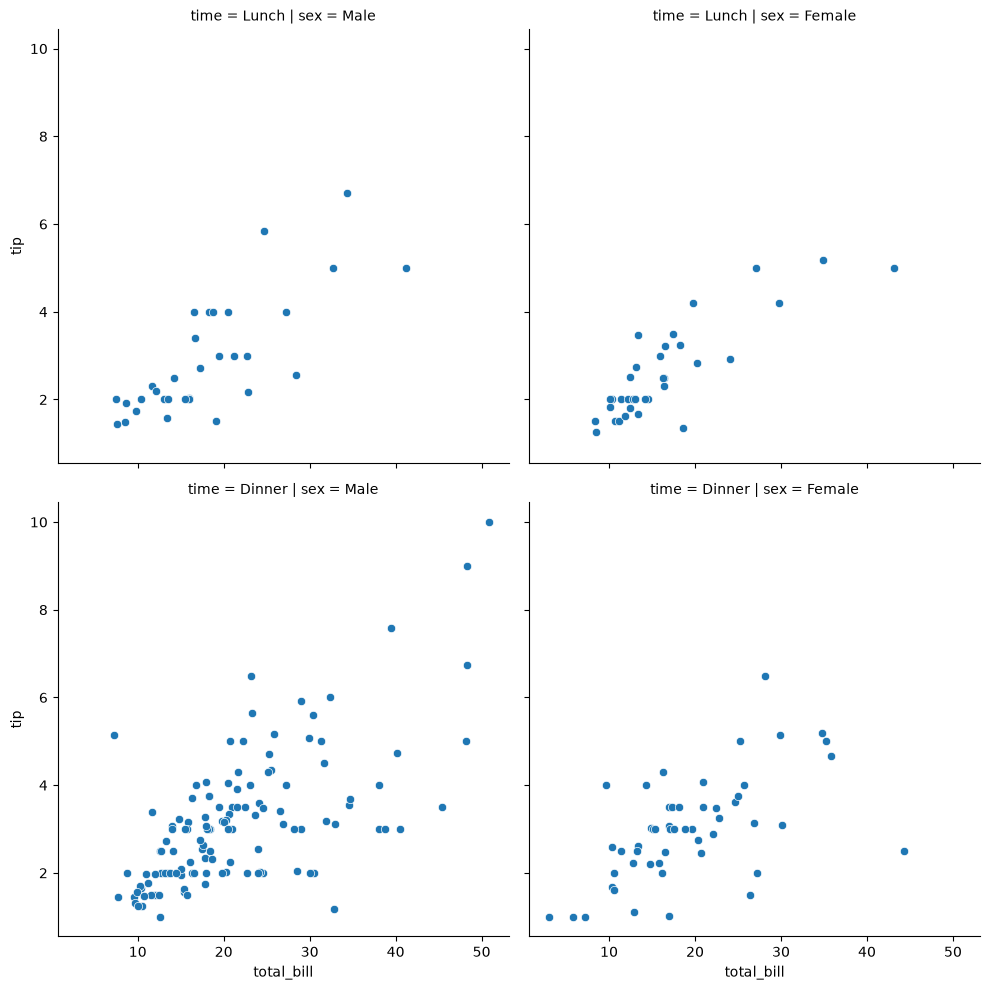

In [29]:
# facet plot

sns.relplot(kind='scatter',data=tips,x='total_bill',y='tip',col='sex', row='time')

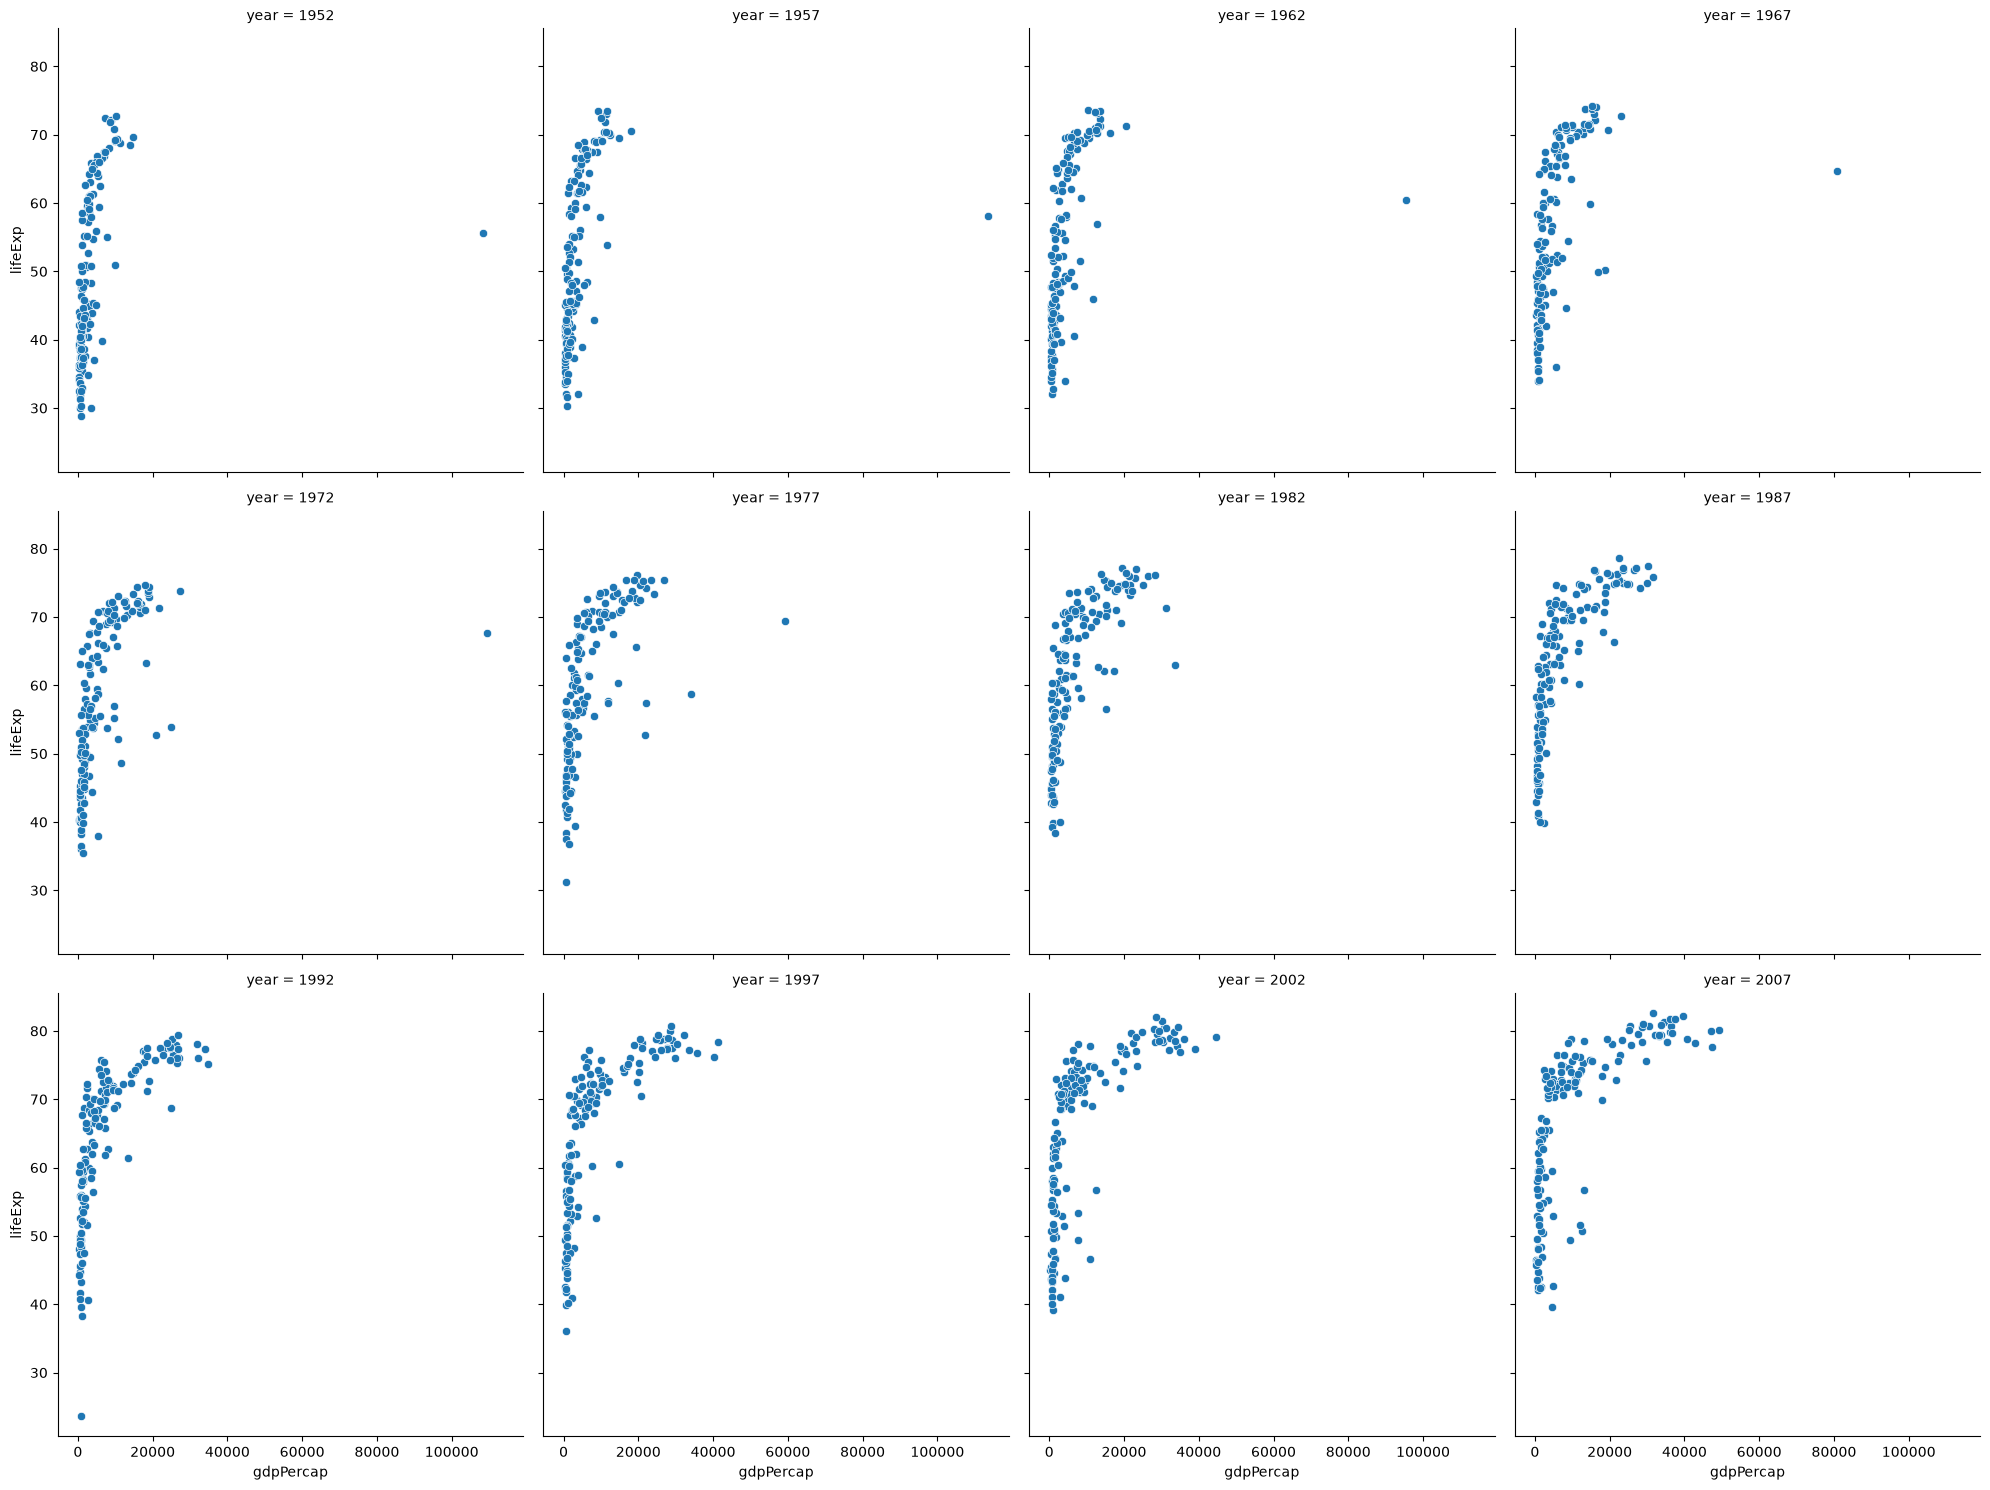

In [ ]:
# col WRap

sns.relplot(data=gap,x='gdpPercap',y='lifeExp',col='year', col_wrap=4) 

# 2. Distribution Plots

- used for univariate analysis
- used to find out the distribution
- Range of the observation
- Central Tendency
- is the data bimodal?
- Are there outliers?

Plots under distribution plot

- histplot
- kdeplot
- rugplot

In [ ]:
# figure level -> displot
# axes level -> histplot -> kdeplot -> rugplot

<Axes: xlabel='total_bill', ylabel='Count'>

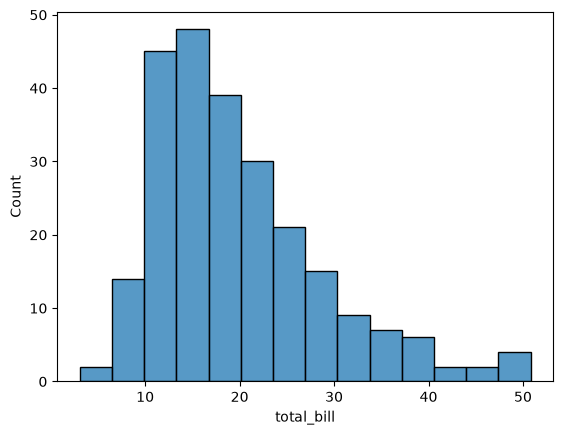

In [33]:
# plotting univariate histogram

sns.histplot(data=tips,x='total_bill')

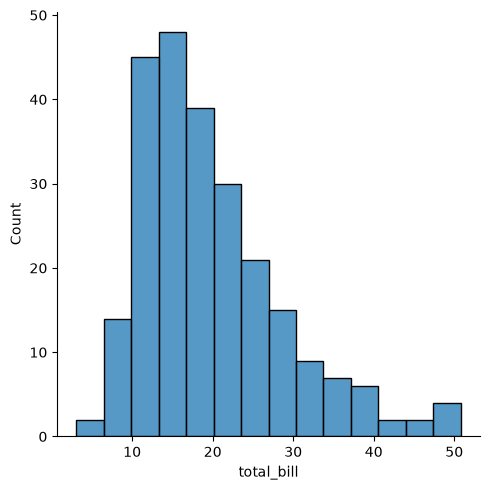

In [35]:
sns.displot(data=tips,x='total_bill',kind='hist')

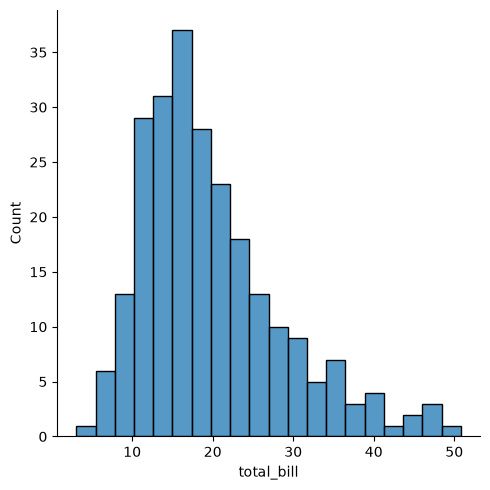

In [36]:
# bins parameter
sns.displot(data=tips,x='total_bill',kind='hist',bins=20)

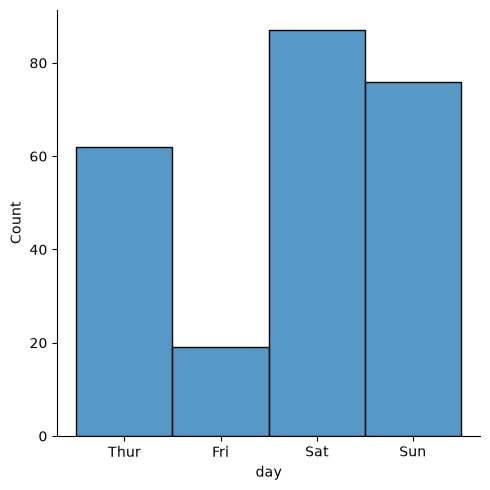

In [ ]:
# It's also possible to visualize the distribution of a categorical variable using the logic of a histogram.
# Discrete bins are automatically set for categorical variables

# also called countplot
sns.displot(data=tips,x='day',kind='hist')

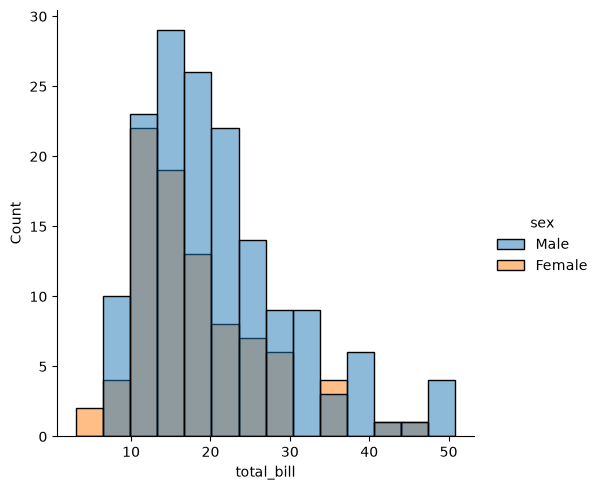

In [41]:
# hue parameter
sns.displot(data=tips,x='total_bill',kind='hist',hue='sex')

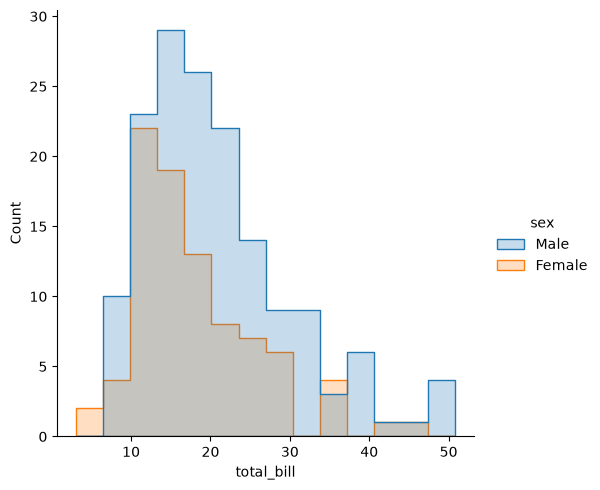

In [42]:
# element -> step

sns.displot(data=tips,x='total_bill',kind='hist',hue='sex',element='step')

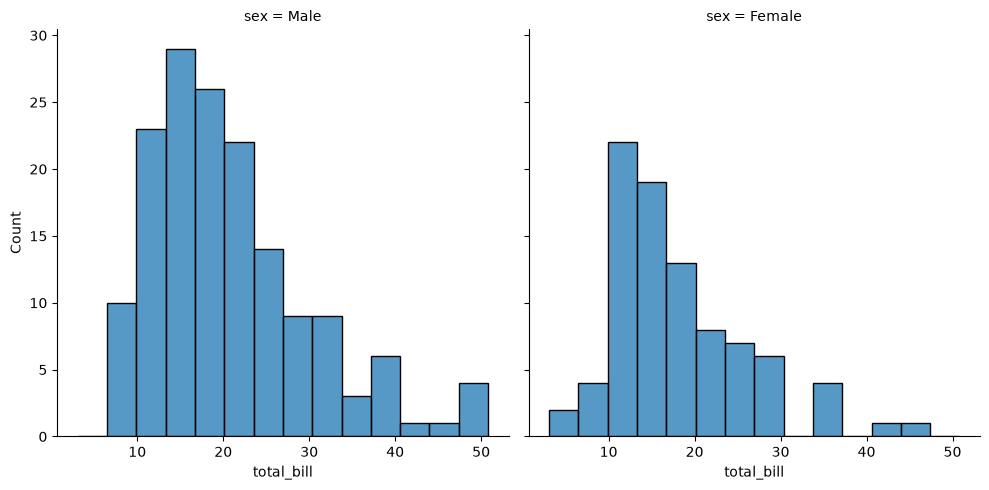

In [44]:
# faceting using col and row
sns.displot(data=tips,x='total_bill',kind='hist',col='sex')

Kdeplot

<Axes: xlabel='total_bill', ylabel='Density'>

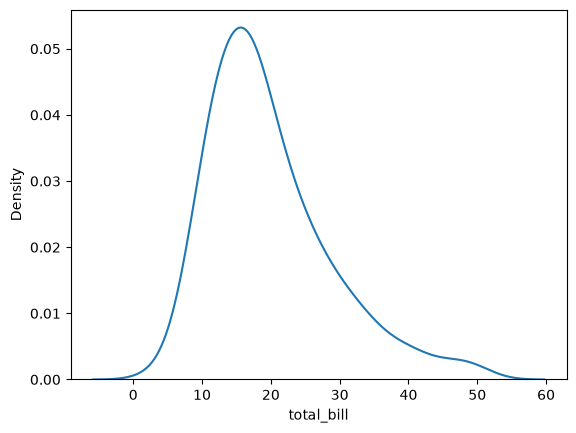

In [ ]:
# kdeplot
# Rather than using discrete bins, a KDE plot smooths the observations with a Gaussian kernel, producing a continuous density estimate

sns.kdeplot(data=tips,x='total_bill')

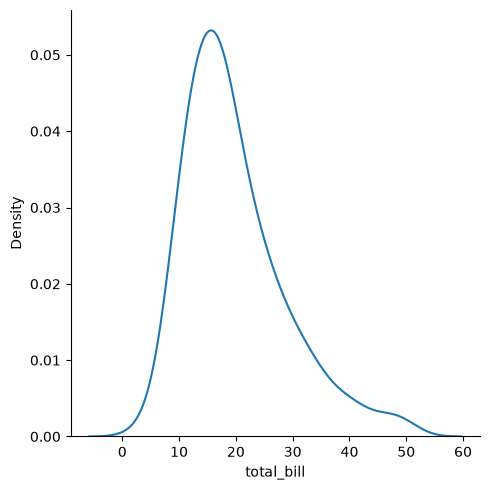

In [46]:
# displot
sns.displot(data=tips,x='total_bill',kind='kde')

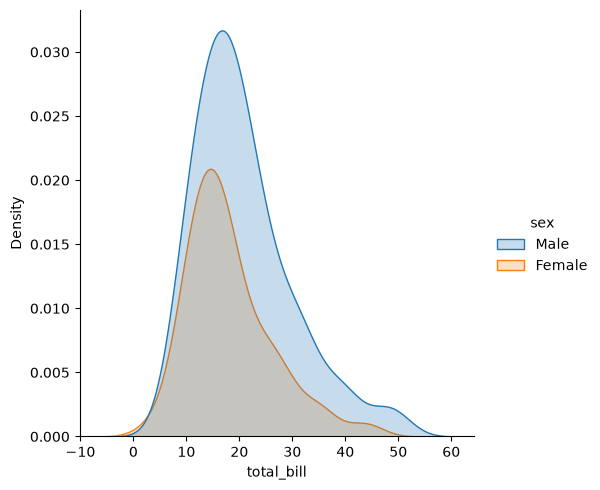

In [48]:
# hue -> fill
sns.displot(data=tips,x='total_bill',kind='kde',hue='sex',fill=True)

<Axes: xlabel='total_bill', ylabel='Density'>

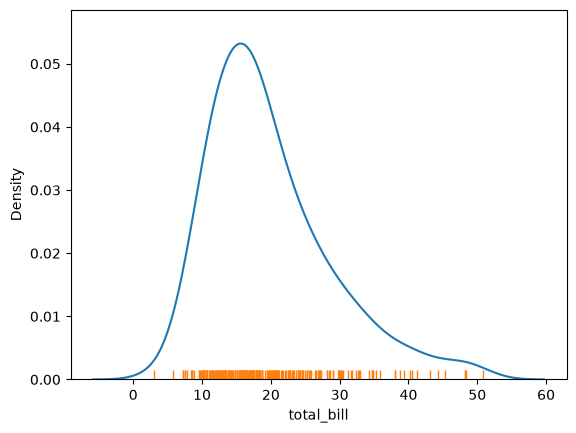

In [ ]:
# Rugplot

# Plot marginal distributions by drawing ticks along the x and y axes.

# This function is intended to complement other plots by showing the location of individual observations in an unobtrusive way.

sns.kdeplot(data=tips,x='total_bill')
sns.rugplot(data=tips,x='total_bill')

<Axes: xlabel='total_bill', ylabel='tip'>

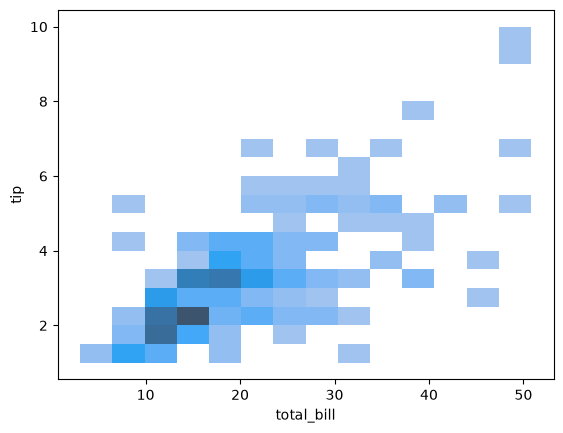

In [52]:
# Bivariate histogram
# A bivariate histogram bins the data within rectangles that tile the plot
# and then shows the count of observations within each rectangle with the fill color

sns.histplot(data=tips,x='total_bill',y='tip')

<Axes: xlabel='total_bill', ylabel='tip'>

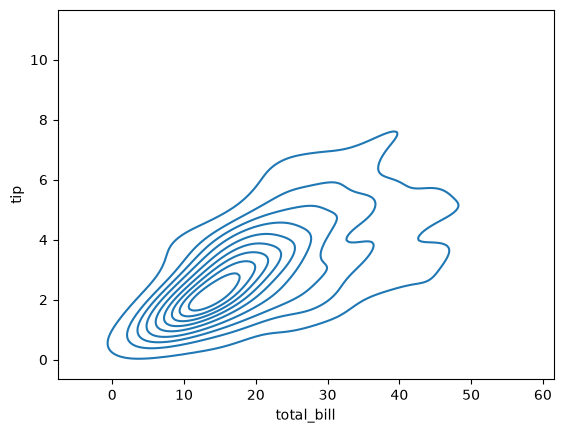

In [53]:
# Bivariate Kdeplot
# a bivariate KDE plot smoothes the (x, y) observations with a 2D Gaussian

sns.kdeplot(data=tips,x='total_bill',y='tip')


# Matrix Plot

- Heatmap
- Clustermap

<Axes: xlabel='year', ylabel='country'>

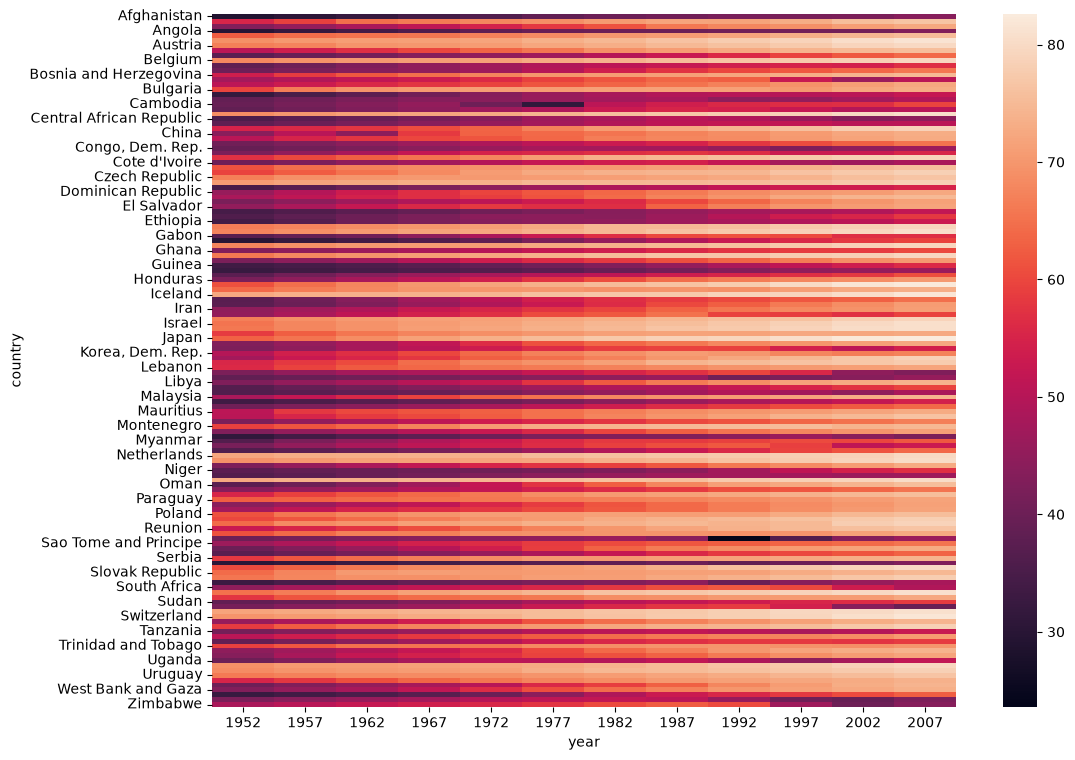

In [ ]:
# Heatmap

# Plot rectangular data as a color-encoded matrix

temp_df = gap.pivot(index='country',columns='year',values='lifeExp')

# heatmap -> axes level function
plt.figure(figsize=(12,9)) 
sns.heatmap(temp_df)

<Axes: xlabel='year', ylabel='country'>

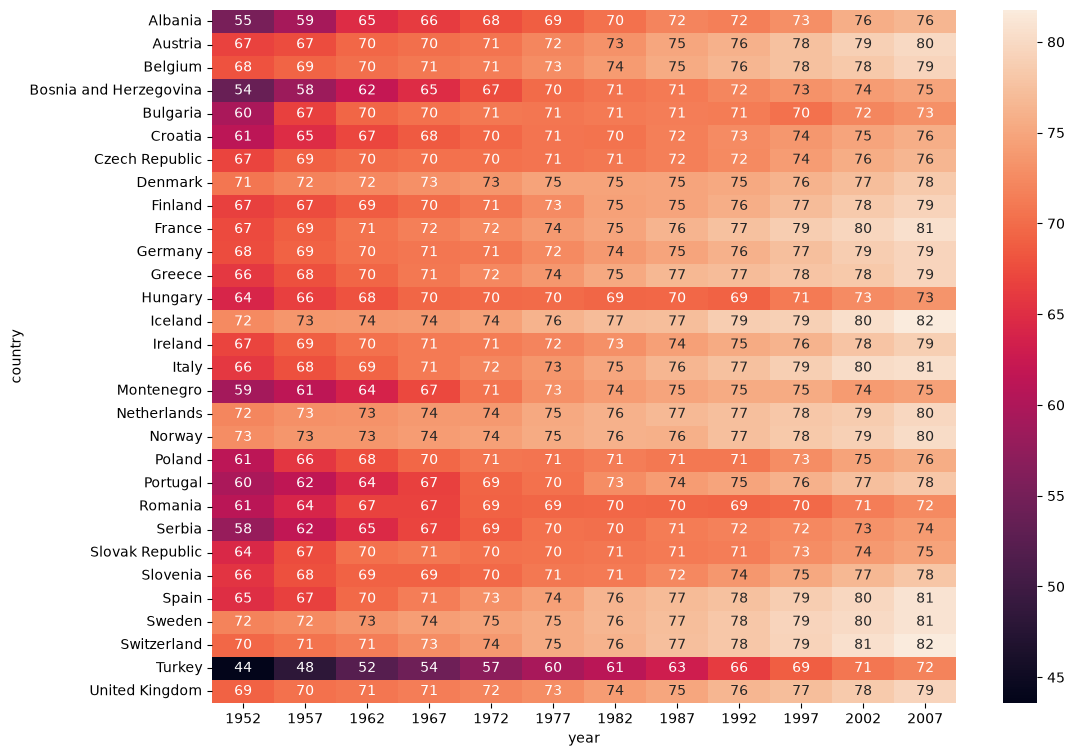

In [62]:
# annot
temp_df = gap[gap['continent'] == 'Europe'].pivot(index='country',columns='year',values='lifeExp')

plt.figure(figsize=(12,9)) 
sns.heatmap(temp_df,annot=True)

<Axes: xlabel='year', ylabel='country'>

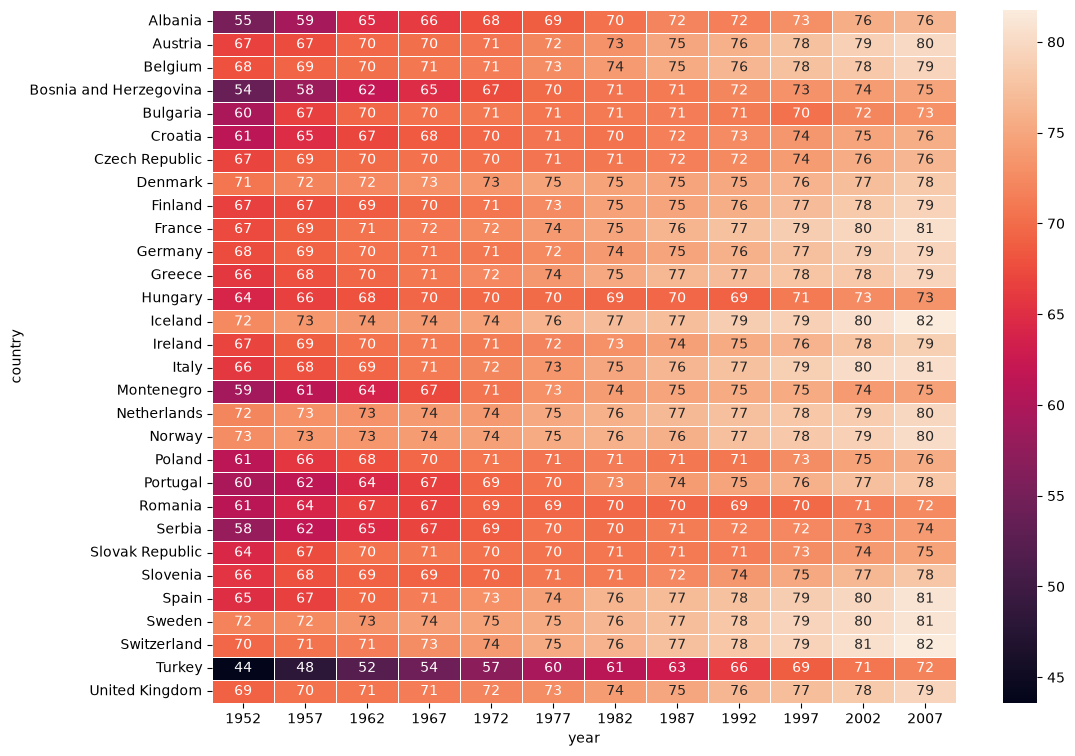

In [64]:
# linewidth
temp_df = gap[gap['continent'] == 'Europe'].pivot(index='country',columns='year',values='lifeExp')

plt.figure(figsize=(12,9)) 
sns.heatmap(temp_df,annot=True,linewidths=0.5)

<Axes: xlabel='year', ylabel='country'>

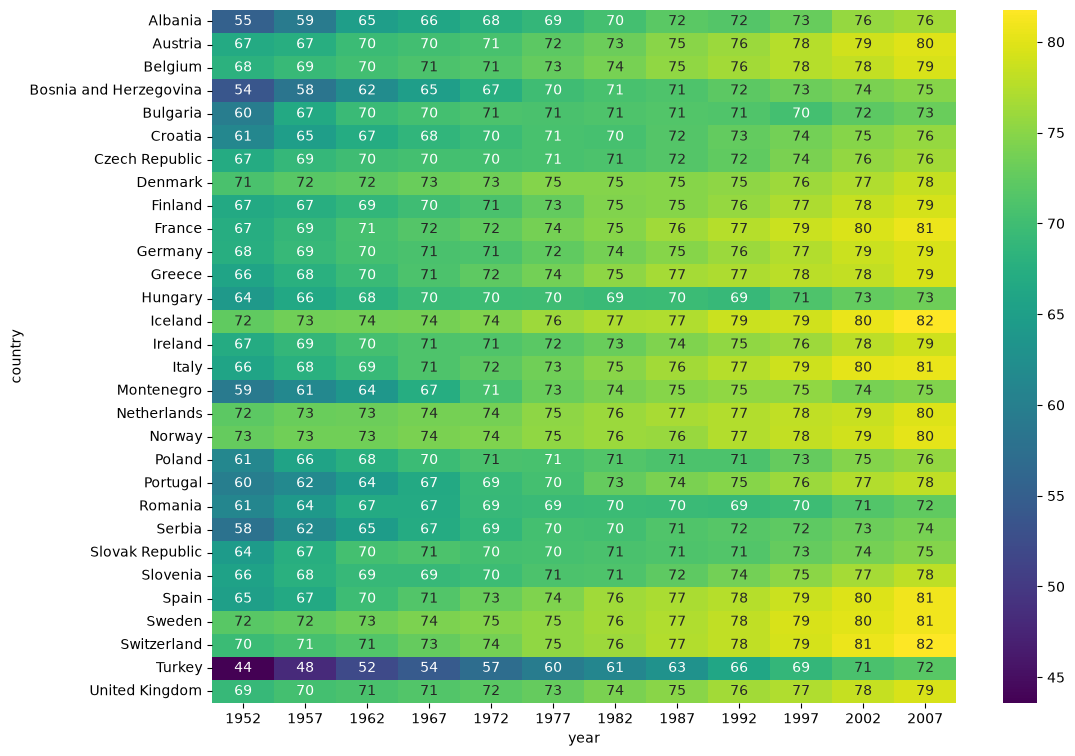

In [63]:
# cmap
temp_df = gap[gap['continent'] == 'Europe'].pivot(index='country',columns='year',values='lifeExp')

plt.figure(figsize=(12,9)) 
sns.heatmap(temp_df,annot=True,cmap='viridis')

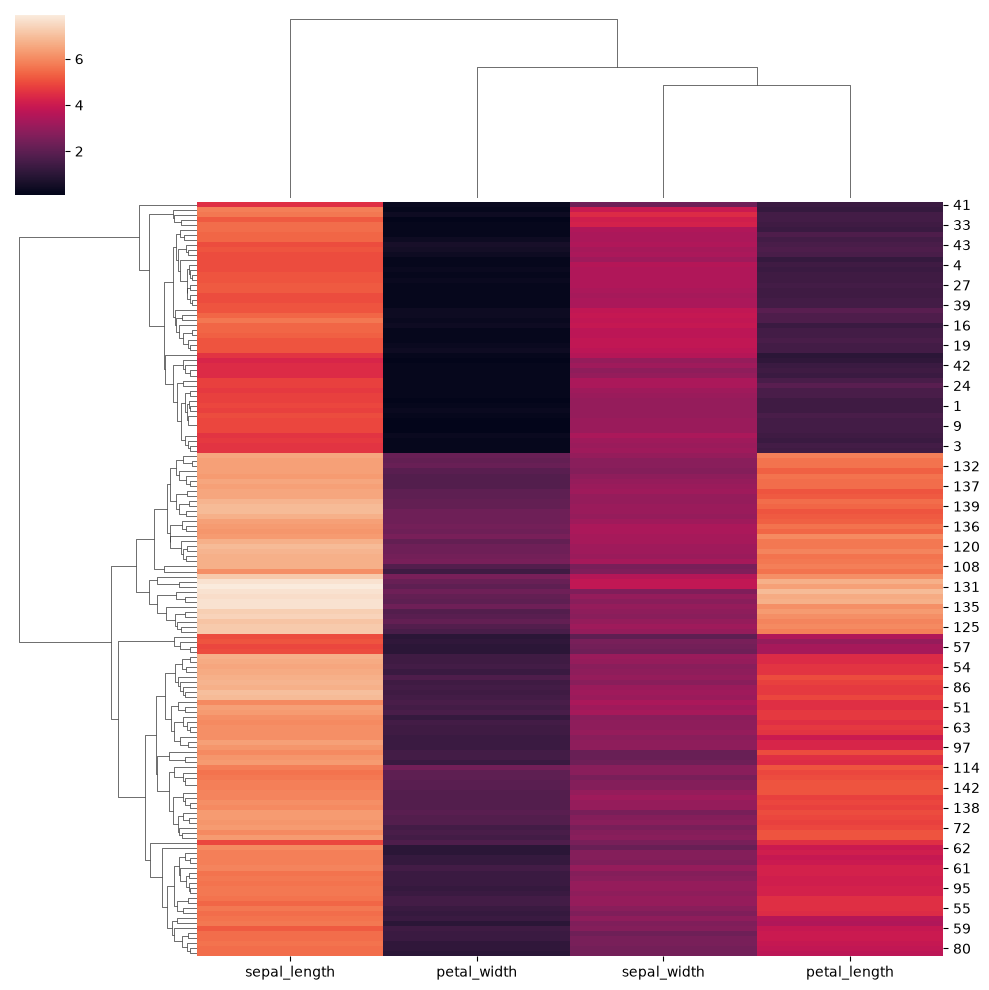

In [71]:
# Clustermap

iris = px.data.iris()
iris

sns.clustermap(iris.iloc[:,[0,1,2,3]])